# Credit Scoring Model
Goal: predict whether a customer will have a serious delinquency (90+ days late) within 2 years, using the Give Me Some Credit dataset. Only about 6.7% of customers default, so the classes are imbalanced.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

## 1. Load and explore the data
Loaded the data with pandas and checked its size, column types, missing values, and the balance of the target column. The target is imbalanced, so accuracy alone is misleading.

In [2]:
from google.colab import files
uploaded = files.upload()   # a button appears; choose cs-training.csv

df = pd.read_csv("cs-training.csv", index_col=0)

Saving cs-training.csv to cs-training (1).csv


In [3]:
print(df.shape)          # (rows, columns)
df.head()                # first 5 rows
df.info()                # column names, types, non-empty counts
print(df.isnull().sum()) # missing values per column
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))

(150000, 11)
<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float

## 2. Data cleaning
- Removed duplicate rows.
- Removed rows with an impossible age (0).
- Removed rows where the late-payment columns held the special codes 96/98, which are not real counts.
- Removed rows where credit utilization was above 10, which is almost certainly an error.
- DebtRatio had huge values for customers whose income was missing, so I set it to missing for those rows and added an IncomeMissing flag instead of deleting 20% of the data.

In [4]:
for col in ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio"]:
    bad = df[pd.to_numeric(df[col], errors="coerce").isnull()][col]
    print(col, "->", len(bad), "non-numeric values")
    print(bad.unique()[:10])

RevolvingUtilizationOfUnsecuredLines -> 0 non-numeric values
[]
DebtRatio -> 0 non-numeric values
[]


In [5]:
print(df.shape)
print(df["SeriousDlqin2yrs"].value_counts(normalize=True))
print("duplicate rows:", df.duplicated().sum())
df.describe().T

(150000, 11)
SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64
duplicate rows: 609


,count,mean,std,min,25%,50%,75%,max
SeriousDlqin2yrs,150000.0,0.066840,0.249746,0.0,0.000000,0.000000,0.000000,1.0
RevolvingUtilizationOfUnsecuredLines,150000.0,6.048438,249.755371,0.0,0.029867,0.154181,0.559046,50708.0
age,150000.0,52.295207,14.771866,0.0,41.000000,52.000000,63.000000,109.0
NumberOfTime30-59DaysPastDueNotWorse,150000.0,0.421033,4.192781,0.0,0.000000,0.000000,0.000000,98.0
DebtRatio,150000.0,353.005076,2037.818523,0.0,0.175074,0.366508,0.868254,329664.0
MonthlyIncome,120269.0,6670.221237,14384.674215,0.0,3400.000000,5400.000000,8249.000000,3008750.0
NumberOfOpenCreditLinesAndLoans,150000.0,8.452760,5.145951,0.0,5.000000,8.000000,11.000000,58.0
NumberOfTimes90DaysLate,150000.0,0.265973,4.169304,0.0,0.000000,0.000000,0.000000,98.0
NumberRealEstateLoansOrLines,150000.0,1.018240,1.129771,0.0,0.000000,1.000000,2.000000,54.0
NumberOfTime60-89DaysPastDueNotWorse,150000.0,0.240387,4.155179,0.0,0.000000,0.000000,0.000000,98.0


In [6]:
df = df.drop_duplicates()
print(df.shape)

(149391, 11)


In [7]:
print("age < 18:", (df["age"] < 18).sum())
print("age > 100:", (df["age"] > 100).sum())
print()
for col in ["NumberOfTime30-59DaysPastDueNotWorse",
            "NumberOfTimes90DaysLate",
            "NumberOfTime60-89DaysPastDueNotWorse"]:
    print(col)
    print(df[col].value_counts().sort_index().tail(6))
    print()
print("Utilization > 1:", (df["RevolvingUtilizationOfUnsecuredLines"] > 1).sum())
print("Utilization > 10:", (df["RevolvingUtilizationOfUnsecuredLines"] > 10).sum())
print("DebtRatio > 1:", (df["DebtRatio"] > 1).sum())
print("DebtRatio > 100:", (df["DebtRatio"] > 100).sum())

age < 18: 1
age > 100: 13

NumberOfTime30-59DaysPastDueNotWorse
NumberOfTime30-59DaysPastDueNotWorse
10      4
11      1
12      2
13      1
96      5
98    220
Name: count, dtype: int64

NumberOfTimes90DaysLate
NumberOfTimes90DaysLate
13      4
14      2
15      2
17      1
96      5
98    220
Name: count, dtype: int64

NumberOfTime60-89DaysPastDueNotWorse
NumberOfTime60-89DaysPastDueNotWorse
7       9
8       2
9       1
11      1
96      5
98    220
Name: count, dtype: int64

Utilization > 1: 3321
Utilization > 10: 241
DebtRatio > 1: 35130
DebtRatio > 100: 24378


In [8]:
before = len(df)

# 1. impossible ages
df = df[df["age"] >= 18]

# 2. the 96/98 special codes
codes = ((df["NumberOfTime30-59DaysPastDueNotWorse"] >= 96) |
         (df["NumberOfTimes90DaysLate"] >= 96) |
         (df["NumberOfTime60-89DaysPastDueNotWorse"] >= 96))
print("rows with 96/98 codes:", codes.sum())
df = df[~codes]
print("removed in total:", before - len(df), "| shape now:", df.shape)

# 3. investigate the huge DebtRatio values
high = df["DebtRatio"] > 100
print("\nDebtRatio > 100 rows:", high.sum())
print("of those, income is missing:", df.loc[high, "MonthlyIncome"].isnull().sum())
print("default rate in those rows:", round(df.loc[high, "SeriousDlqin2yrs"].mean(), 4))
print("default rate overall:", round(df["SeriousDlqin2yrs"].mean(), 4))

rows with 96/98 codes: 225
removed in total: 226 | shape now: (149165, 11)

DebtRatio > 100 rows: 24375
of those, income is missing: 22688
default rate in those rows: 0.0577
default rate overall: 0.0662


## 3. Feature engineering
Created new columns the models can use more easily: TotalLatePayments, HasLatePayment, IncomePerPerson. Customers with a late payment defaulted about 8 times more often (22% vs 2.7%), so HasLatePayment is a strong signal.

In [9]:
df = df[df["RevolvingUtilizationOfUnsecuredLines"] <= 10].copy()

df["IncomeMissing"] = df["MonthlyIncome"].isnull().astype(int)
df.loc[df["MonthlyIncome"].isnull(), "DebtRatio"] = np.nan

print(df.shape)
print(df.isnull().sum())
print(df.groupby("IncomeMissing")["SeriousDlqin2yrs"].mean())

(148924, 12)
SeriousDlqin2yrs                            0
RevolvingUtilizationOfUnsecuredLines        0
age                                         0
NumberOfTime30-59DaysPastDueNotWorse        0
DebtRatio                               29073
MonthlyIncome                           29073
NumberOfOpenCreditLinesAndLoans             0
NumberOfTimes90DaysLate                     0
NumberRealEstateLoansOrLines                0
NumberOfTime60-89DaysPastDueNotWorse        0
NumberOfDependents                       3798
IncomeMissing                               0
dtype: int64
IncomeMissing
0    0.068894
1    0.054999
Name: SeriousDlqin2yrs, dtype: float64


In [10]:
late_cols = ["NumberOfTime30-59DaysPastDueNotWorse",
             "NumberOfTimes90DaysLate",
             "NumberOfTime60-89DaysPastDueNotWorse"]

df["TotalLatePayments"] = df[late_cols].sum(axis=1)
df["HasLatePayment"] = (df["TotalLatePayments"] > 0).astype(int)
df["IncomePerPerson"] = df["MonthlyIncome"] / (df["NumberOfDependents"] + 1)

print(df.shape)
print(df.groupby("HasLatePayment")["SeriousDlqin2yrs"].agg(["mean", "count"]))

(148924, 15)
                    mean   count
HasLatePayment                  
0               0.027381  118877
1               0.219689   30047


## 4. Train/test split
Split the data 80/20 and kept the same default rate in both sets (stratify). Missing values were filled with medians, and extreme values were capped at the 99th percentile, both calculated from the training set only. This avoids data leakage, where information from the test set sneaks into training and makes the score look better than it really is.

In [11]:
from sklearn.model_selection import train_test_split

X = df.drop(columns="SeriousDlqin2yrs")
y = df["SeriousDlqin2yrs"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# fill gaps using TRAINING medians only
medians = X_train.median()
X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

# cap extreme values at the TRAINING 99th percentile
cap_cols = ["RevolvingUtilizationOfUnsecuredLines", "DebtRatio",
            "MonthlyIncome", "IncomePerPerson"]
upper = X_train[cap_cols].quantile(0.99)
X_train[cap_cols] = X_train[cap_cols].clip(upper=upper, axis=1)
X_test[cap_cols] = X_test[cap_cols].clip(upper=upper, axis=1)

print("train:", X_train.shape, "| test:", X_test.shape)
print("missing values left:", X_train.isnull().sum().sum(), X_test.isnull().sum().sum())
print("default rate  train:", round(y_train.mean(), 4), "| test:", round(y_test.mean(), 4))

train: (119139, 14) | test: (29785, 14)
missing values left: 0 0
default rate  train: 0.0662 | test: 0.0662


In [13]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier

models = {
    "Dummy (always 0)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(class_weight="balanced", max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, min_samples_leaf=50,
        class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=10, min_samples_leaf=20,
        class_weight="balanced_subsample", n_jobs=-1, random_state=42),
}

for name, model in models.items():
    model.fit(X_train, y_train)
    acc = model.score(X_test, y_test)
    print(f"{name:22s} accuracy on test set: {acc:.4f}")

Dummy (always 0)       accuracy on test set: 0.9338
Logistic Regression    accuracy on test set: 0.7978
Decision Tree          accuracy on test set: 0.7640
Random Forest          accuracy on test set: 0.8184


## 6. Evaluation
The dummy model scores 93% accuracy but catches zero defaulters, so I compared the models using Precision, Recall, F1-Score and ROC-AUC. Random Forest was slightly best (AUC 0.863), but the three models are close. The balanced setting catches more defaulters (high recall) at the cost of more false alarms (low precision).

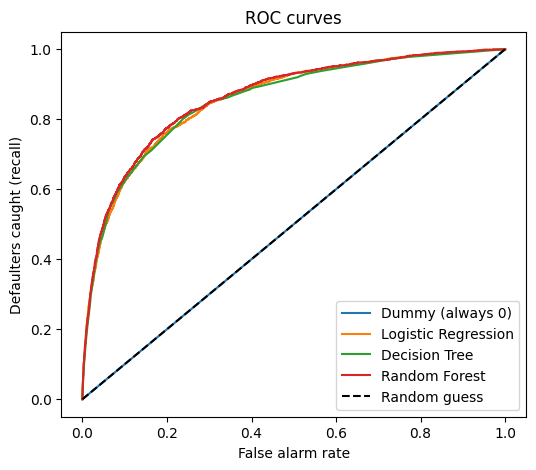

                     Precision  Recall  F1-Score  ROC-AUC
Model                                                    
Dummy (always 0)        0.0000  0.0000    0.0000   0.5000
Logistic Regression     0.2129  0.7620    0.3328   0.8574
Decision Tree           0.1923  0.8021    0.3102   0.8554
Random Forest           0.2310  0.7489    0.3531   0.8630


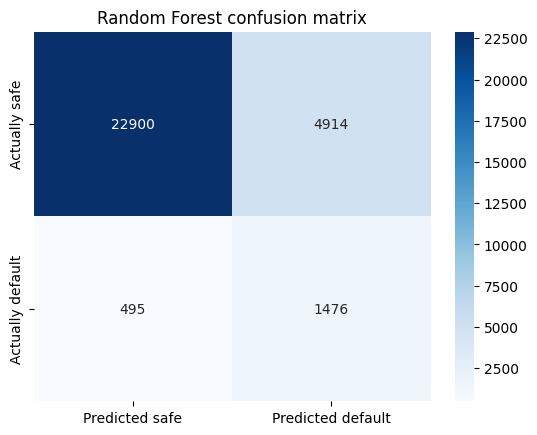

In [14]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve)

rows = []
plt.figure(figsize=(6, 5))

for name, model in models.items():
    pred = model.predict(X_test)                    # yes/no verdict
    proba = model.predict_proba(X_test)[:, 1]       # risk probability
    rows.append({
        "Model": name,
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred),
        "F1-Score": f1_score(y_test, pred),
        "ROC-AUC": roc_auc_score(y_test, proba),
    })
    fpr, tpr, _ = roc_curve(y_test, proba)
    plt.plot(fpr, tpr, label=name)

plt.plot([0, 1], [0, 1], "k--", label="Random guess")
plt.xlabel("False alarm rate")
plt.ylabel("Defaulters caught (recall)")
plt.title("ROC curves")
plt.legend()
plt.show()

results = pd.DataFrame(rows).set_index("Model").round(4)
print(results)

# confusion matrix for the Random Forest
cm = confusion_matrix(y_test, models["Random Forest"].predict(X_test))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted safe", "Predicted default"],
            yticklabels=["Actually safe", "Actually default"])
plt.title("Random Forest confusion matrix")
plt.show()

## 7. Feature importance
The most important features were credit utilization and the late-payment features, including the two I created. IncomeMissing added almost nothing.

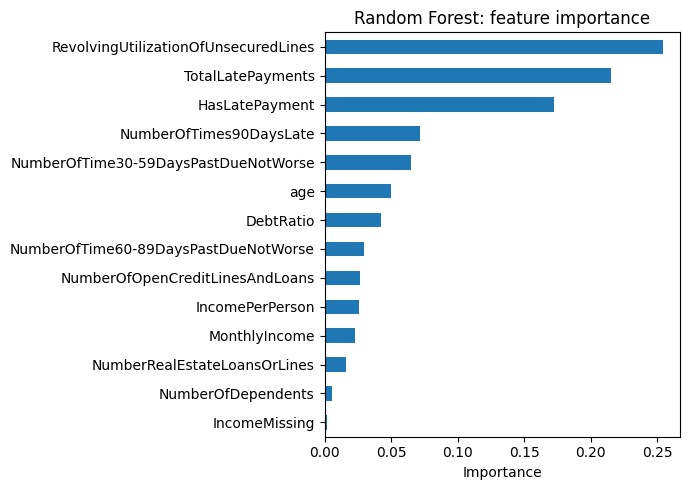

RevolvingUtilizationOfUnsecuredLines    0.255
TotalLatePayments                       0.215
HasLatePayment                          0.172
NumberOfTimes90DaysLate                 0.072
NumberOfTime30-59DaysPastDueNotWorse    0.065
dtype: float64


In [15]:
rf = models["Random Forest"]
importances = pd.Series(rf.feature_importances_, index=X_train.columns).sort_values()

importances.plot(kind="barh", figsize=(7, 5))
plt.title("Random Forest: feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

results.to_csv("model_results.csv")
print(importances.sort_values(ascending=False).head(5).round(3))